# Историческая LTV по когортам

Когорта: месяц первой платной подписки (сумма оплаты больше нуля), когорты с июля 2015 года.
LTV: накопленная выручка на одного клиента когорты по месяцам жизни (возраст 0 это месяц первой оплаты).
Выручка: `actual_amount_paid` в тайваньских долларах, транзакции без отмен, без дисконтирования и без затрат.
Платёж относится к месяцу транзакции, поэтому длинные тарифы, оплаченные сразу, дают всплески выручки.
Теория: `docs/ltv.md`.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

P = "/workspace/data/processed/"
LAST_MONTH = pd.Timestamp("2017-03-01")
C_FROM, C_TO, MAX_AGE = "2015-07-01", "2016-12-01", 24
FULL_TO = "2016-03-01"  # последняя когорта, наблюдаемая все 12 месяцев
INK, BLUE, ORANGE = "#2b2f36", "#0072B2", "#E69F00"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cdd4",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8eaee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

con = duckdb.connect()
con.execute(
    "SET memory_limit='4GB'; SET threads=2; SET enable_progress_bar=false; "
    "SET temp_directory='/workspace/data/_duckdb_tmp'"
)
con.execute(f'''
    CREATE VIEW tr AS
    SELECT *
    FROM '{P}transactions.parquet'
''')
_ = con.execute(f'''
    CREATE VIEW anc AS
    SELECT *
    FROM '{P}user_anchors.parquet'
''')

## Выручка по когортам и возрастам
Для каждой пары «когорта, возраст»: сколько клиентов платили в этом месяце и сколько денег получено.
Платежи одного клиента в одном месяце суммируются.

In [2]:
rev = con.sql(f'''
    WITH coh AS (
        SELECT
            msno,
            first_paid_month AS cohort
        FROM anc
        WHERE first_paid_month BETWEEN DATE '{C_FROM}' AND DATE '{C_TO}'
    ),
    pay AS (
        SELECT
            msno,
            date_trunc('month', transaction_date)::DATE AS pay_month,
            sum(actual_amount_paid) AS amount
        FROM tr
        WHERE is_cancel = 0
            AND actual_amount_paid > 0
        GROUP BY msno, 2
    ),
    cohort_size AS (
        SELECT
            cohort,
            count(*) AS size
        FROM coh
        GROUP BY cohort
    )
    SELECT
        coh.cohort,
        date_diff('month', coh.cohort, pay.pay_month) AS age,
        count(*) AS payers,
        sum(pay.amount) AS revenue,
        any_value(cohort_size.size) AS size
    FROM coh
    JOIN pay USING (msno)
    JOIN cohort_size ON cohort_size.cohort = coh.cohort
    WHERE pay.pay_month >= coh.cohort
        AND date_diff('month', coh.cohort, pay.pay_month) <= {MAX_AGE}
    GROUP BY coh.cohort, 2
''').df()

sizes = rev.groupby("cohort")["size"].first()
ages = list(range(MAX_AGE + 1))


def to_grid(col: str) -> pd.DataFrame:
    '''Строит таблицу «когорта × возраст» с нулями в наблюдаемых клетках и пропусками за концом данных.

    Args:
        col (str): столбец из `rev` (`payers` или `revenue`).

    Returns:
        pd.DataFrame: строки это когорты, столбцы это возраст в месяцах.
    '''
    g = rev.pivot(index="cohort", columns="age", values=col).reindex(index=sizes.index, columns=ages)
    observed = np.array([[(c + pd.DateOffset(months=a)) <= LAST_MONTH for a in ages] for c in g.index])
    return g.where(~observed | g.notna(), 0.0).where(observed)


revenue, payers = to_grid("revenue"), to_grid("payers")
rpc = revenue.div(sizes, axis=0)  # выручка на одного клиента когорты
cum = rpc.cumsum(axis=1)  # накопленная выручка (LTV по возрастам)
pd.DataFrame({
    "когорт": [len(sizes)],
    "клиентов всего": [int(sizes.sum())],
    "платили в месяце 0, % (проверка, ожидается 100)": [round(100 * (payers[0] / sizes).mean(), 1)],
})

,когорт,клиентов всего,"платили в месяце 0, % (проверка, ожидается 100)"
0,18,875327,100.0


## Накопленная выручка на клиента
Каждая линия это одна когорта (светлые линии ранние когорты, тёмные поздние), линия обрывается там, где кончаются данные.
Пунктир: средняя по когортам, полностью наблюдаемым 12 месяцев (с 2015-07 по 2016-03), с весами по размеру когорты.

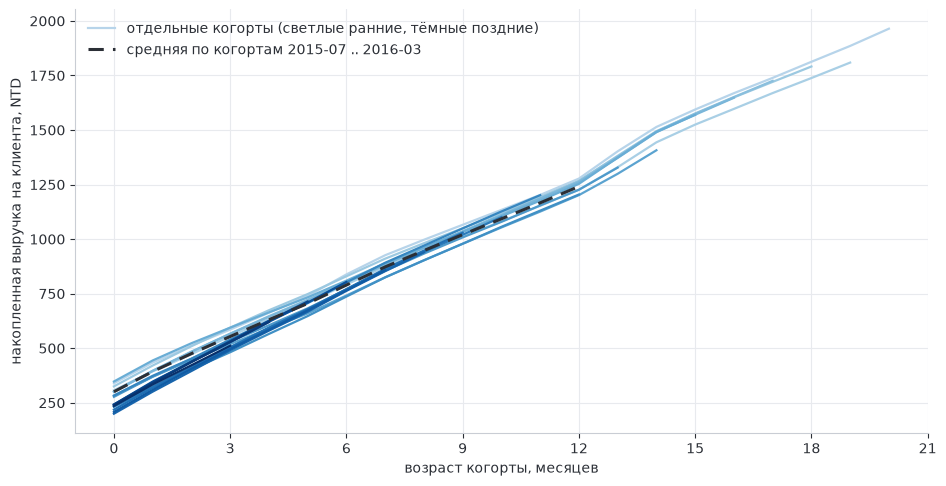

In [3]:
full = sizes.index[sizes.index <= pd.Timestamp(FULL_TO)]
mean_cum = (revenue.loc[full].sum() / sizes.loc[full].sum()).cumsum()

fig, ax = plt.subplots(figsize=(11, 5.5))
cmap = plt.get_cmap("Blues")
for i, c in enumerate(cum.index):
    s = cum.loc[c].dropna()
    ax.plot(s.index, s, color=cmap(0.3 + 0.7 * i / (len(cum) - 1)), lw=1.6)
ax.plot(mean_cum.index[:13], mean_cum.iloc[:13], color=INK, lw=2.2, ls=(0, (5, 3)))
ax.set_xlabel("возраст когорты, месяцев")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylabel("накопленная выручка на клиента, NTD")
ax.legend(handles=[
    Line2D([], [], color=cmap(0.3), lw=1.6, label="отдельные когорты (светлые ранние, тёмные поздние)"),
    Line2D([], [], color=INK, lw=2.2, ls=(0, (5, 3)), label="средняя по когортам 2015-07 .. 2016-03"),
], frameon=False, loc="upper left")
plt.show()

## LTV по когортам на горизонтах 3, 6 и 12 месяцев
Когорты 2015-07 .. 2016-03 (каждая наблюдается все 12 месяцев). Накопленная выручка на клиента, NTD.

In [4]:
tbl = cum.loc[full, [2, 5, 11]].copy()
tbl.columns = ["LTV 3 мес", "LTV 6 мес", "LTV 12 мес"]
tbl.insert(0, "клиентов", sizes.loc[full].astype(int))
tbl.index = tbl.index.strftime("%Y-%m")
mean_row = pd.DataFrame(
    {"клиентов": [int(sizes.loc[full].sum())],
     "LTV 3 мес": [mean_cum[2]], "LTV 6 мес": [mean_cum[5]], "LTV 12 мес": [mean_cum[11]]},
    index=["среднее"],
)
pd.concat([tbl, mean_row]).round(0)

,клиентов,LTV 3 мес,LTV 6 мес,LTV 12 мес
2015-07,51254,512.0,740.0,1202.0
2015-08,57376,473.0,709.0,1153.0
2015-09,52160,509.0,748.0,1193.0
2015-10,63449,482.0,722.0,1187.0
2015-11,61401,484.0,718.0,1185.0
2015-12,56816,523.0,733.0,1176.0
2016-01,76538,446.0,659.0,1126.0
2016-02,60746,451.0,683.0,1154.0
2016-03,50265,403.0,647.0,1130.0
среднее,530005,475.0,705.0,1166.0


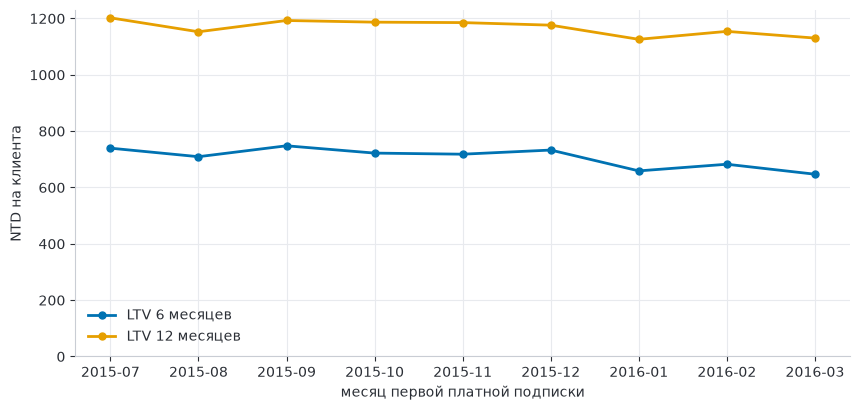

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = full.strftime("%Y-%m")
ax.plot(x, cum.loc[full, 5], color=BLUE, lw=2, marker="o", ms=5, label="LTV 6 месяцев")
ax.plot(x, cum.loc[full, 11], color=ORANGE, lw=2, marker="o", ms=5, label="LTV 12 месяцев")
ax.set_xlabel("месяц первой платной подписки")
ax.set_ylabel("NTD на клиента")
ax.set_ylim(0, None)
ax.legend(frameon=False, loc="lower left")
plt.show()

## Из чего складывается выручка
Выручка на клиента когорты в месяце равна доле платящих в этом месяце, умноженной на средний платёж платящего.
Средние по когортам 2015-07 .. 2016-03 с весами по размеру когорты.

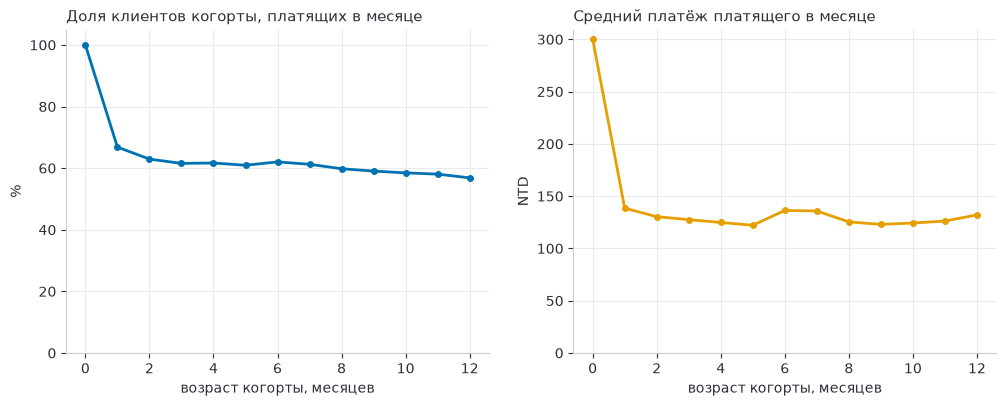

age,0,1,2,3,4,5,6,7,8,9,10,11,12
"доля платящих, %",100.0,66.8,62.9,61.5,61.7,60.9,62.0,61.2,59.8,59.0,58.5,58.1,56.9
"средний платёж, NTD",300.0,139.0,130.0,128.0,125.0,122.0,136.0,136.0,125.0,123.0,124.0,126.0,132.0


In [6]:
share_payers = payers.loc[full].sum() / sizes.loc[full].sum()
avg_payment = revenue.loc[full].sum() / payers.loc[full].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(range(13), 100 * share_payers.iloc[:13], color=BLUE, lw=2, marker="o", ms=4)
axes[0].set_title("Доля клиентов когорты, платящих в месяце", loc="left", fontsize=11)
axes[0].set_ylabel("%")
axes[0].set_ylim(0, 105)
axes[1].plot(range(13), avg_payment.iloc[:13], color=ORANGE, lw=2, marker="o", ms=4)
axes[1].set_title("Средний платёж платящего в месяце", loc="left", fontsize=11)
axes[1].set_ylabel("NTD")
axes[1].set_ylim(0, None)
for ax in axes:
    ax.set_xlabel("возраст когорты, месяцев")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()
pd.DataFrame({
    "доля платящих, %": (100 * share_payers.iloc[:13]).round(1),
    "средний платёж, NTD": avg_payment.iloc[:13].round(0),
}).T

## Выводы
- **Накопленная выручка растёт почти линейно.** Первая оплата в среднем 300 NTD (часто сразу за несколько месяцев вперёд), дальше каждый месяц добавляет в среднем около 72 NTD на клиента когорты: примерно 60% платящих, умноженные на 122–139 NTD среднего платежа.
- **LTV за 12 месяцев в среднем 1166 NTD на клиента** (по когортам 2015-07 .. 2016-03 от 1126 до 1202). Когорты 2016 года ниже когорт второй половины 2015 примерно на 4% (1126–1154 против 1153–1202); на горизонте 3 месяцев разрыв больше (403–451 против 473–523). Причина не исследовалась.
- **Доля платящих** падает со 100% (месяц 0) до 67% в месяце 1, держится на 61–62% в месяцах 2–7 и снижается до 57% к 12-му месяцу. Это ниже доли активных клиентов из ноутбука о когортах (74% к 12-му месяцу): клиенты с длинными тарифами активны, не платя в данном месяце.
- **Средний платёж** платящего: 300 NTD в месяце 0, затем 122–139 NTD, к 12-му месяцу 132 NTD. Платёж месяца 0 вдвое выше, потому что первая оплата нередко приходится на длинный тариф.
- **Излом около 12-го месяца:** после него кривая идёт чуть круче. Возможная причина (не проверена) в продлениях длинных и годовых тарифов.
- **Ограничения:** платёж относится к месяцу транзакции, поэтому длинные тарифы дают разовые всплески; возвраты денег в данных не выделены; суммы в тайваньских долларах, без дисконтирования, это выручка, а не прибыль.